# 08. Currents

Positions and dates are shifted, so public current and wind data won't match. What we can learn about how the water and wind move Scout has to come from the telemetry itself. Two independent views:

**Part 1. Drift with the motor off.** In MANUAL the motor is off (nb 06), so any movement is current + wind. Split by arming:
- **MANUAL disarmed:** the motor can't run at all
- **MANUAL armed:** motor allowed, but no command (nb 06: ~0 W propulsion, same as disarmed)

For each leg (from the mission, nb 05): where it went, in which direction and how fast. Then the same thing hour by hour, because tidal currents turn round about every 6 h and a long leg averages them out.

**Part 2. Power vs heading with the motor on.** At the same speed over ground, going against the current should cost more power than going with it. (Moved here from nb 06.)

**Part 3. Both together** on one compass.

Speed over ground (SOG) = speed relative to the seabed, from GPS: it includes current and wind, not just the motor.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch

plt.rcParams.update({"figure.figsize": (14, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a

HOTEL_W, STARLINK_W, K_V = 10, 22, 64.81      # nb 06 (locked): hotel, Starlink, k of the k·v motor model
MODE_NAMES = {0: "MANUAL", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}
MODE_COLORS = {0: "#9e9e9e", 10: "#2ca02c", 16: "#9467bd", 17: "#d62728"}
ARM_COLORS = {"MANUAL disarmed": "#6baed6", "MANUAL armed": "#08519c"}

# Starlink on = inside a session (messages < 2 min apart) +- 30 s, same rule as nb 06
direct = df[df.communication_mode == "direct"]
sid = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(sid).t.agg(start="min", end="max")
df["starlink"] = False
for s in sessions.itertuples():
    df.loc[df.t.between(s.start - pd.Timedelta("30s"), s.end + pd.Timedelta("30s")), "starlink"] = True

# per-minute means, as in nb 06
m = (df.dropna(subset=["P_load"]).set_index("t").resample("1min")
       .agg({"P_load": "mean", "groundspeed_ms": "mean", "custom_mode": "last", "custom0_arming": "last", "starlink": "max"})
       .dropna(subset=["P_load"]).reset_index())
m["starlink"] = m.starlink.astype(bool)
m["armed"] = m.custom0_arming == 1
m["P_prop"] = m.P_load - HOTEL_W - STARLINK_W * m.starlink

# the mission (nb 05): one line per mode / arming change
lines = pd.read_csv("../data/mission_modes.csv", parse_dates=["from", "to"], index_col="#")
fix = df[df.latitude_deg.between(55, 70)][["t", "latitude_deg", "longitude_deg"]]
lat_mid = fix.latitude_deg.median()
M_PER_DEG_LAT, M_PER_DEG_LON = 110_540, 111_320 * np.cos(np.radians(lat_mid))
print(f"{len(lines)} mission lines, {len(m)} minutes with load, {len(fix)} fixes")

95 mission lines, 5899 minutes with load, 24670 fixes


# Part 1. Drift with the motor off

## 1. Each MANUAL leg: where it went

For every MANUAL leg of 30 min or more: the straight line from its first fix to its last.
- **net drift speed** = that distance / the time between the two fixes
- **direction** = where the boat went *to* (0° = north, 90° = east). Oceanographers give currents the same way ("sets towards").
- **path speed** = distance along the track / time. Path ≫ net means the drift wandered (e.g. turned with the tide).

**14 Jul before 10:30 is left out of the averages** (drawn, but marked): the boat moved at ~1.9 m/s while disarmed, too fast for drift (nb 03, probably towed), and the first leg only has hourly Iridium fixes.

In [2]:
TOW_END = pd.Timestamp("2025-07-14 10:30", tz="UTC")

def leg_drift(r):
    f = fix[(fix.t >= r["from"]) & (fix.t < r["to"])]
    if len(f) < 2:
        return pd.Series(dtype=float)
    dx = np.diff(f.longitude_deg) * M_PER_DEG_LON; dy = np.diff(f.latitude_deg) * M_PER_DEG_LAT
    e = (f.longitude_deg.iloc[-1] - f.longitude_deg.iloc[0]) * M_PER_DEG_LON
    n = (f.latitude_deg.iloc[-1] - f.latitude_deg.iloc[0]) * M_PER_DEG_LAT
    dt = (f.t.iloc[-1] - f.t.iloc[0]).total_seconds()
    return pd.Series({"east (m/s)": e / dt, "north (m/s)": n / dt, "net speed (m/s)": np.hypot(e, n) / dt,
                      "direction (°)": np.degrees(np.arctan2(e, n)) % 360, "path speed (m/s)": np.hypot(dx, dy).sum() / dt,
                      "lon0": f.longitude_deg.iloc[0], "lat0": f.latitude_deg.iloc[0],
                      "lon1": f.longitude_deg.iloc[-1], "lat1": f.latitude_deg.iloc[-1], "fixes": len(f)})

man = lines[(lines["mode"] == "MANUAL") & (lines.hours >= 0.5)].copy()
man["kind"] = np.where(man.armed, "MANUAL armed", "MANUAL disarmed")
man = man.join(man.apply(leg_drift, axis=1))
man["in averages"] = man["from"] >= TOW_END
print(f"{len(man)} MANUAL legs ≥ 30 min: " + ", ".join(f"{k} {v}" for k, v in man.kind.value_counts().items())
      + f"; {(~man['in averages']).sum()} on 14 Jul before 10:30 left out of the averages")

17 MANUAL legs ≥ 30 min: MANUAL armed 12, MANUAL disarmed 5; 4 on 14 Jul before 10:30 left out of the averages


**Two maps, side by side:** MANUAL disarmed (left) and MANUAL armed (right). Each arrow goes from the leg's first fix to its last; colour = net drift speed (same scale on both). The leg's own track is drawn thin in the same colour. Dashed arrows = 14 Jul before 10:30 (not in the averages). Whole track in light grey.

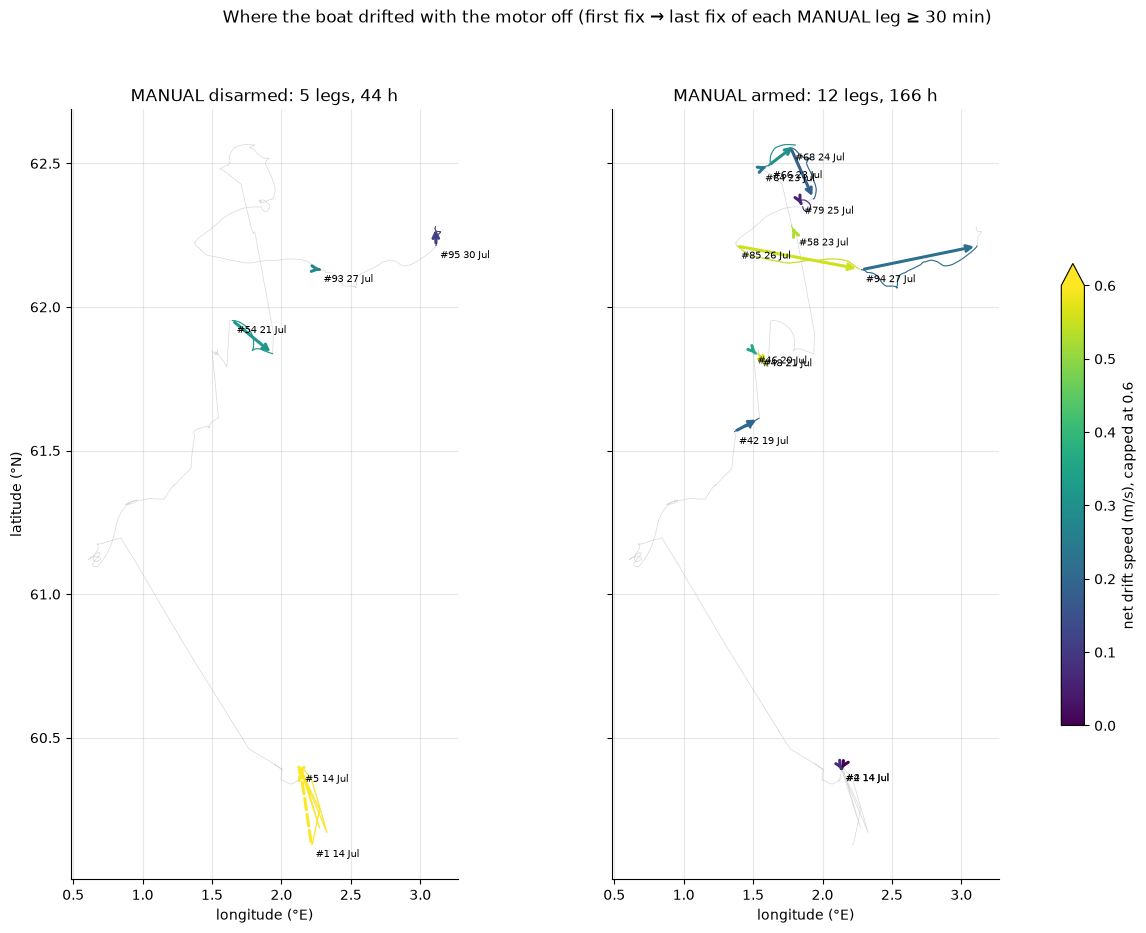

In [3]:
norm = plt.Normalize(0, 0.6)
cmap = plt.cm.viridis
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharex=True, sharey=True)
for ax, kind in zip(axes, ARM_COLORS):
    ax.plot(fix.longitude_deg, fix.latitude_deg, "-", lw=0.5, color="0.85", zorder=0)
    for k, r in man[man.kind == kind].iterrows():
        f = fix[(fix.t >= r["from"]) & (fix.t < r["to"])]
        c = cmap(norm(min(r["net speed (m/s)"], 0.6)))
        ax.plot(f.longitude_deg, f.latitude_deg, "-", lw=0.8, color=c, zorder=1)
        ax.annotate("", xy=(r.lon1, r.lat1), xytext=(r.lon0, r.lat0), zorder=2,
                    arrowprops=dict(arrowstyle="->", color=c, lw=2.2, ls="-" if r["in averages"] else "--"))
        ax.annotate(f"#{k} {r['from']:%d %b}", (r.lon0, r.lat0), fontsize=7, xytext=(3, -9), textcoords="offset points")
    n = (man.kind == kind).sum()
    ax.set_title(f"{kind}: {n} legs, {man[man.kind == kind].hours.sum():.0f} h")
    ax.set_aspect(1 / np.cos(np.radians(lat_mid))); ax.set_xlabel("longitude (°E)")
axes[0].set_ylabel("latitude (°N)")
fig.colorbar(plt.cm.ScalarMappable(cmap=cmap, norm=norm), ax=axes, shrink=0.6, label="net drift speed (m/s), capped at 0.6", extend="max")
fig.suptitle("Where the boat drifted with the motor off (first fix → last fix of each MANUAL leg ≥ 30 min)")
plt.show()

**Compass roses.** For each kind, the share of drift *time* going towards each 30° sector (bars, weighted by leg hours), and the **time-weighted mean drift** as an arrow: Σ(displacement) / Σ(time), which is what a long stay would add up to. Only legs in the averages.

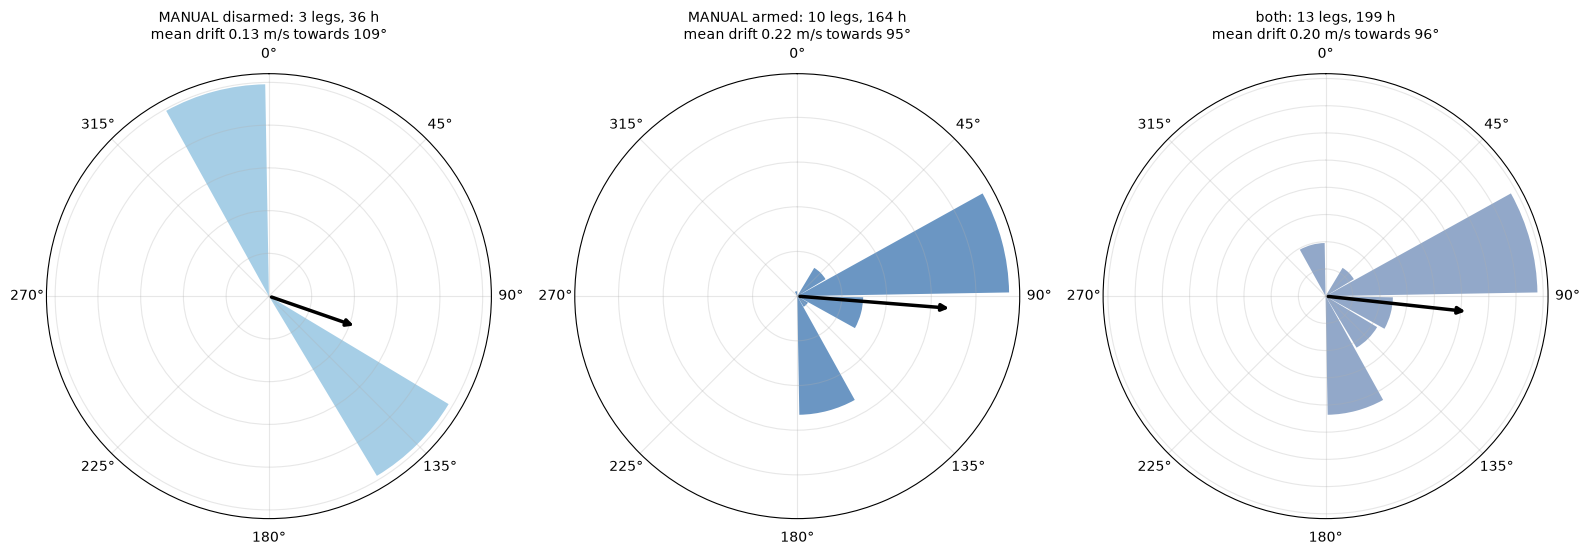

,legs,hours,mean drift (m/s),towards (°),east (m/s),north (m/s),median leg net speed (m/s),median leg path speed (m/s)
MANUAL disarmed,3.0,35.66,0.13,109.13,0.12,-0.04,0.28,0.28
MANUAL armed,10.0,163.78,0.22,94.52,0.22,-0.02,0.27,0.32
both,13.0,199.43,0.20,96.19,0.20,-0.02,0.28,0.28


In [4]:
def mean_drift(d):
    """Time-weighted mean drift vector of a set of legs: total displacement / total time."""
    T = (d.hours * 3600).sum()
    e = (d["east (m/s)"] * d.hours * 3600).sum() / T
    n = (d["north (m/s)"] * d.hours * 3600).sum() / T
    return e, n

avg = man[man["in averages"]]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), subplot_kw={"projection": "polar"})
SECT = np.radians(np.arange(0, 360, 30))
for ax, (name, d) in zip(axes, [("MANUAL disarmed", avg[avg.kind == "MANUAL disarmed"]), ("MANUAL armed", avg[avg.kind == "MANUAL armed"]), ("both", avg)]):
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    h = np.histogram(d["direction (°)"], bins=np.arange(0, 361, 30), weights=d.hours)[0]
    ax.bar(SECT + np.radians(15), h / h.sum() if h.sum() else h, width=np.radians(28), color=ARM_COLORS.get(name, "#4a6fa5"), alpha=0.6)
    e, n = mean_drift(d)
    sp, dr = np.hypot(e, n), np.degrees(np.arctan2(e, n)) % 360
    r = (h / h.sum()).max() if h.sum() else 1
    ax.annotate("", xy=(np.radians(dr), r * min(1, sp / 0.3)), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2.5))
    ax.set_title(f"{name}: {len(d)} legs, {d.hours.sum():.0f} h\nmean drift {sp:.2f} m/s towards {dr:.0f}°", fontsize=10)
    ax.set_yticklabels([])
plt.tight_layout(); plt.show()

summ = pd.DataFrame({name: {"legs": len(d), "hours": d.hours.sum(),
                            "mean drift (m/s)": np.hypot(*mean_drift(d)), "towards (°)": np.degrees(np.arctan2(*mean_drift(d))) % 360,
                            "east (m/s)": mean_drift(d)[0], "north (m/s)": mean_drift(d)[1],
                            "median leg net speed (m/s)": d["net speed (m/s)"].median(), "median leg path speed (m/s)": d["path speed (m/s)"].median()}
                     for name, d in [("MANUAL disarmed", avg[avg.kind == "MANUAL disarmed"]), ("MANUAL armed", avg[avg.kind == "MANUAL armed"]), ("both", avg)]}).T
summ.round(2)

In [5]:
(man[["from", "hours", "kind", "net speed (m/s)", "path speed (m/s)", "direction (°)", "east (m/s)", "north (m/s)", "fixes", "in averages"]]
   .style.format({"from": "{:%d %b %H:%M}", "hours": "{:.1f}", "net speed (m/s)": "{:.2f}", "path speed (m/s)": "{:.2f}",
                  "direction (°)": "{:.0f}", "east (m/s)": "{:+.2f}", "north (m/s)": "{:+.2f}"}))

,from,hours,kind,net speed (m/s),path speed (m/s),direction (°),east (m/s),north (m/s),fixes,in averages
#,,,,,,,,,,
1,14 Jul 00:20,7.5,MANUAL disarmed,1.10,4.98,352,-0.16,+1.09,52.000000,False
2,14 Jul 07:48,0.6,MANUAL armed,0.00,0.07,210,-0.00,-0.00,1929.000000,False
4,14 Jul 08:23,1.2,MANUAL armed,0.08,0.16,150,+0.04,-0.07,2128.000000,False
5,14 Jul 09:36,0.6,MANUAL disarmed,1.57,1.63,192,-0.34,-1.54,2068.000000,False
42,19 Jul 22:10,15.3,MANUAL armed,0.20,0.23,62,+0.17,+0.09,482.000000,True
46,20 Jul 22:00,1.5,MANUAL armed,0.36,0.36,136,+0.25,-0.26,67.000000,True
48,21 Jul 07:55,3.1,MANUAL armed,0.56,0.57,143,+0.34,-0.45,106.000000,True
54,21 Jul 18:28,17.5,MANUAL disarmed,0.32,0.42,129,+0.25,-0.20,829.000000,True
58,23 Jul 05:50,1.8,MANUAL armed,0.53,0.53,338,-0.20,+0.49,12.000000,True


## 2. Hour by hour: does the drift turn with the tide?

A leg of 20 h averages over several tides, so its net drift is only what's left after the tide cancels. Here every MANUAL leg is cut into **1-hour pieces**: position interpolated at the start and end of each hour (only hours fully inside a leg with a fix at least every 20 min), velocity = displacement / 1 h.

Top: the east component. Middle: the north component. Bottom: speed. One dot per hour, coloured by arming. A tidal current would show as a wave with a period of about 12.4 h.

184 one-hour drift pieces (MANUAL armed 152, MANUAL disarmed 32)


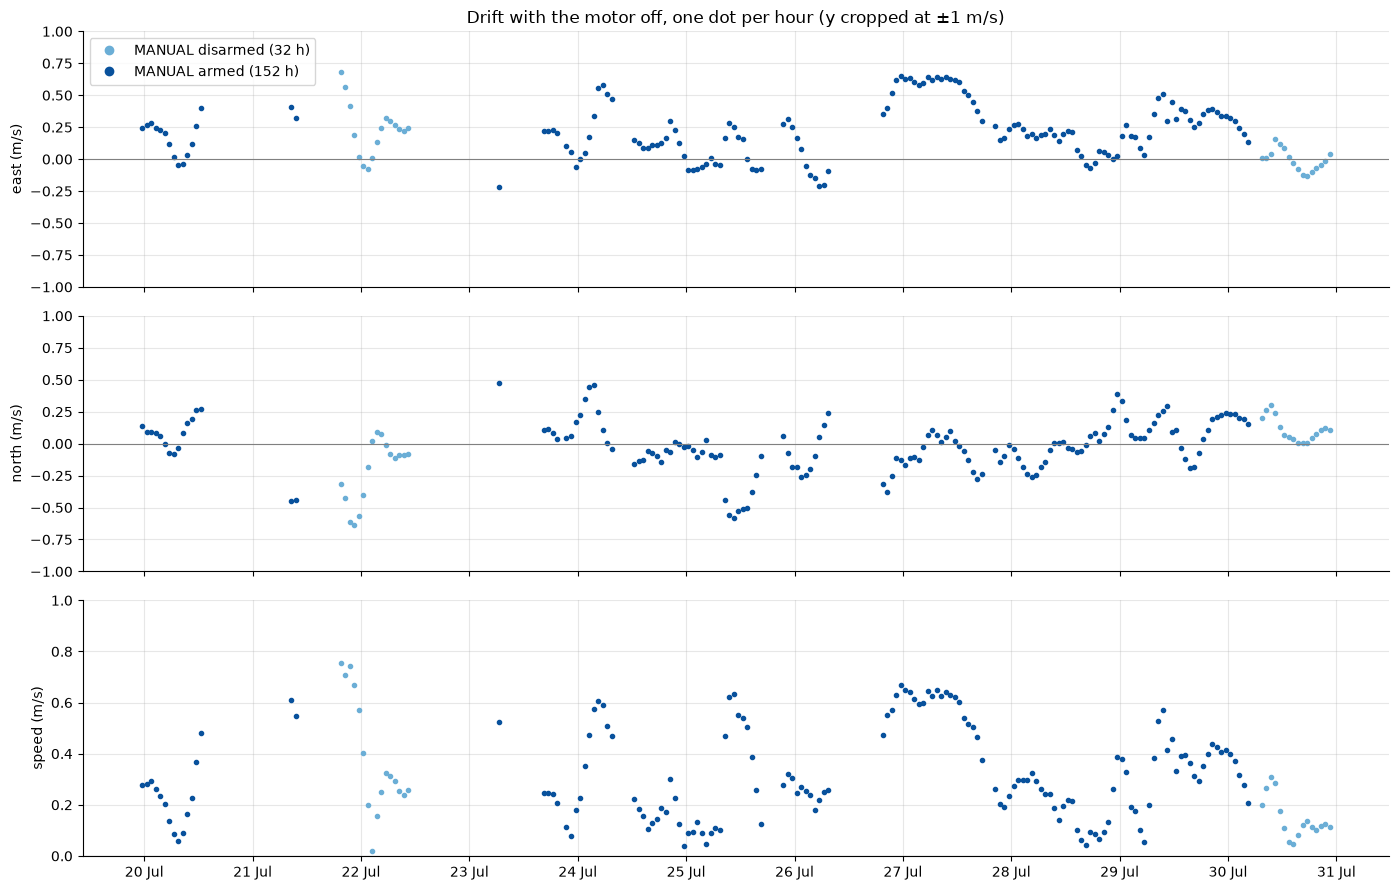

In [6]:
def hourly_drift(r, max_gap="20min"):
    f = fix[(fix.t >= r["from"]) & (fix.t < r["to"])].set_index("t")
    if len(f) < 3:
        return pd.DataFrame()
    hrs = pd.date_range(f.index[0].ceil("h"), f.index[-1].floor("h"), freq="1h")
    if len(hrs) < 2:
        return pd.DataFrame()
    s = (f.index - f.index[0]).total_seconds().values
    q = (hrs - f.index[0]).total_seconds().values
    lon, lat = np.interp(q, s, f.longitude_deg), np.interp(q, s, f.latitude_deg)
    gaps = pd.Series(f.index).diff().dt.total_seconds().fillna(0).values
    rows = []
    for a, b in zip(range(len(hrs) - 1), range(1, len(hrs))):
        inside = (f.index > hrs[a]) & (f.index <= hrs[b])
        if not inside.any() or gaps[inside].max() > pd.Timedelta(max_gap).total_seconds():
            continue
        e = (lon[b] - lon[a]) * M_PER_DEG_LON / 3600; n = (lat[b] - lat[a]) * M_PER_DEG_LAT / 3600
        rows.append({"t": hrs[a] + pd.Timedelta("30min"), "east": e, "north": n, "speed": np.hypot(e, n), "kind": r["kind"]})
    return pd.DataFrame(rows)

hd = pd.concat([hourly_drift(r) for _, r in man[man["in averages"]].iterrows()], ignore_index=True)
print(f"{len(hd)} one-hour drift pieces (" + ", ".join(f"{k} {v}" for k, v in hd.kind.value_counts().items()) + ")")

fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, col, lab in zip(axes, ["east", "north", "speed"], ["east (m/s)", "north (m/s)", "speed (m/s)"]):
    for kind, c in ARM_COLORS.items():
        g = hd[hd.kind == kind]
        ax.plot(g.t, g[col], "o", ms=3, color=c, label=f"{kind} ({len(g)} h)")
    ax.axhline(0, color="grey", lw=0.8); ax.set_ylabel(lab); ax.set_ylim(-1, 1) if col != "speed" else ax.set_ylim(0, 1)
axes[0].legend(loc="upper left", markerscale=2)
axes[0].set_title("Drift with the motor off, one dot per hour (y cropped at ±1 m/s)")
axes[2].xaxis.set_major_locator(mdates.DayLocator()); axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout(); plt.show()

**Zoom on the longest stretches.** The four longest MANUAL legs, hour by hour, east (light) and north (dark) on the same axis (both are m/s). x = time; the grid lines are 6 h apart, about half a tide.

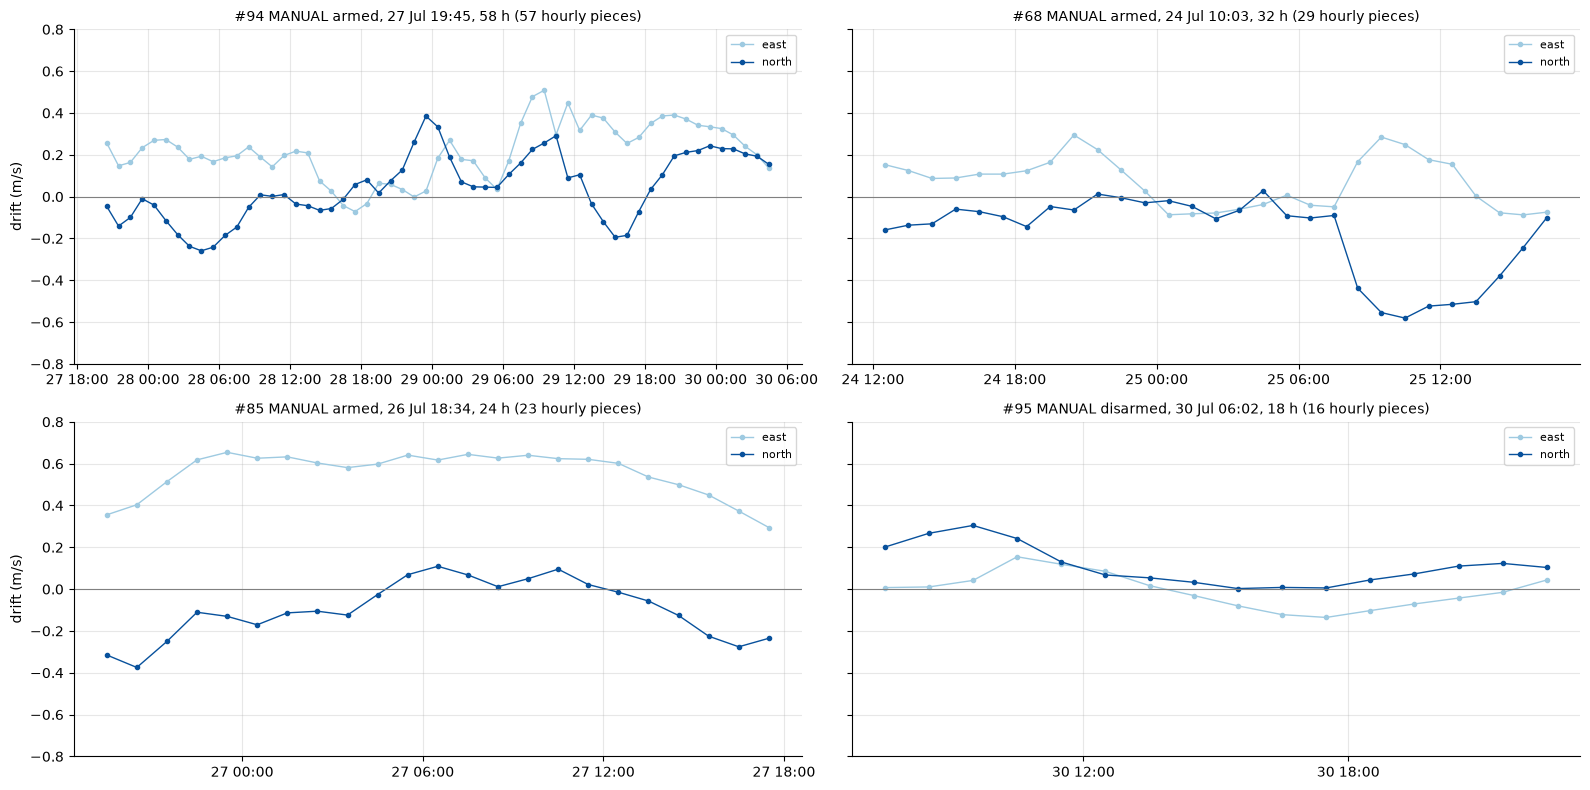

In [7]:
longest = man[man["in averages"]].nlargest(4, "hours")
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharey=True)
for ax, (k, r) in zip(axes.ravel(), longest.iterrows()):
    g = hd[(hd.t >= r["from"]) & (hd.t < r["to"])]
    ax.plot(g.t, g.east, "o-", ms=3, lw=1, color="#9ecae1", label="east")
    ax.plot(g.t, g.north, "o-", ms=3, lw=1, color="#08519c", label="north")
    ax.axhline(0, color="grey", lw=0.8); ax.set_ylim(-0.8, 0.8)
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 6, 12, 18])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %H:00"))
    ax.set_title(f"#{k} {r['kind']}, {r['from']:%d %b %H:%M}, {r.hours:.0f} h ({len(g)} hourly pieces)", fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("drift (m/s)")
plt.tight_layout(); plt.show()

# Part 2. Power vs heading with the motor on

*(Moved here from nb 06.)* At the same speed over ground, the motor should work harder going **against** the current and wind than going **with** them.

- **Minutes:** AUTO and mode 17, armed, SOG ≥ 0.5 m/s (below that the motor is often off, nb 06). Per-minute means.
- **Heading:** `heading_deg` (both links), averaged per minute as a circular mean (so 359° and 1° average to 0°, not 180°). 0° = north, 90° = east.
- **Leftover** = propulsion − 64.8 · v (the k·v model, nb 06). Positive = the motor drew more than the model expects at that speed.
- **W per m/s** = propulsion / SOG: how much power each m/s over ground costs.

Lines = median per 30° heading bin (bins with ≥ 15 minutes), band = middle 50%.

## 3. By mode

2019 motor-on minutes with a heading (AUTO 1389, mode 17 630)


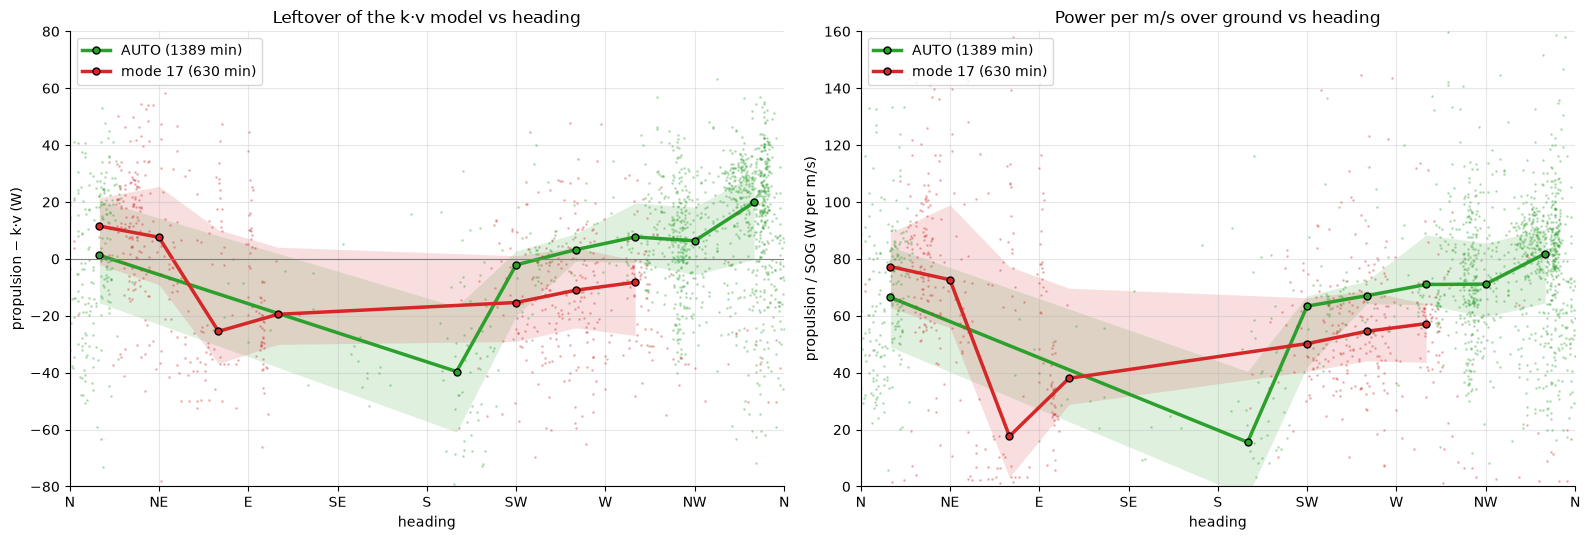

AUTO        mode 17       
         median      n  median      n
0–30°       1.0  210.0    12.0   52.0
30–60°      NaN    NaN     8.0  151.0
60–90°      NaN    NaN   -25.0   60.0
90–120°     NaN    NaN   -19.0   62.0
180–210°  -40.0   50.0     NaN    NaN
210–240°   -2.0   39.0   -15.0   69.0
240–270°    3.0   38.0   -11.0  137.0
270–300°    8.0   94.0    -8.0   69.0
300–330°    6.0  329.0     NaN    NaN
330–360°   20.0  602.0     NaN    NaN

In [8]:
# circular per-minute mean heading, both links
hd = df.dropna(subset=["heading_deg"]).set_index("t")
rad = np.radians(hd.heading_deg)
hmin = pd.DataFrame({"s": np.sin(rad), "c": np.cos(rad)}).resample("1min").mean().dropna()
hmin["heading"] = np.degrees(np.arctan2(hmin.s, hmin.c)) % 360

n_kv, k_kv = 1, K_V
hm = m.merge(hmin[["heading"]], left_on="t", right_index=True)
hm = hm[hm.custom_mode.isin([10, 17]) & hm.armed & (hm.groundspeed_ms >= 0.5)].dropna(subset=["P_prop", "groundspeed_ms"]).copy()
hm["leftover"] = hm.P_prop - k_kv * hm.groundspeed_ms ** n_kv
hm["w_per_ms"] = hm.P_prop / hm.groundspeed_ms
HBINS = np.arange(0, 361, 30)
hm["hbin"] = pd.cut(hm.heading, HBINS, right=False)
print(f"{len(hm)} motor-on minutes with a heading (AUTO {(hm.custom_mode == 10).sum()}, mode 17 {(hm.custom_mode == 17).sum()})")

def by_heading(d, col, min_n=15):
    g = d.groupby("hbin", observed=False)[col]
    out = pd.DataFrame({"x": [b.left + 15 for b in g.median().index], "q25": g.quantile(0.25).values,
                        "median": g.median().values, "q75": g.quantile(0.75).values, "n": g.size().values})
    return out[out.n >= min_n]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, col, ylab, ylim in [(axes[0], "leftover", "propulsion − k·v (W)", (-80, 80)),
                            (axes[1], "w_per_ms", "propulsion / SOG (W per m/s)", (0, 160))]:
    for mode in [10, 17]:
        d = hm[hm.custom_mode == mode]
        ax.plot(d.heading, d[col], ".", ms=2, alpha=0.25, color=MODE_COLORS[mode])
        b = by_heading(d, col)
        ax.fill_between(b.x, b.q25, b.q75, color=MODE_COLORS[mode], alpha=0.15, lw=0)
        ax.plot(b.x, b["median"], "-o", ms=5, lw=2.5, color=MODE_COLORS[mode], mec="k", label=f"{MODE_NAMES[mode]} ({len(d)} min)")
    ax.set_xlim(0, 360); ax.set_xticks(range(0, 361, 45), ["N", "NE", "E", "SE", "S", "SW", "W", "NW", "N"])
    ax.set_ylim(*ylim); ax.set_xlabel("heading"); ax.set_ylabel(ylab); ax.legend(loc="upper left")
axes[0].axhline(0, color="grey", lw=0.8)
axes[0].set_title("Leftover of the k·v model vs heading")
axes[1].set_title("Power per m/s over ground vs heading")
plt.tight_layout(); plt.show()

tab = pd.concat({MODE_NAMES[mo]: by_heading(hm[hm.custom_mode == mo], "leftover").set_index("x")[["median", "n"]] for mo in [10, 17]}, axis=1).sort_index()
tab.index = [f"{int(x - 15)}–{int(x + 15)}°" for x in tab.index]
tab.round(0)

## 4. Both modes merged

Power per m/s over ground against heading, AUTO and mode 17 in one set. The number of minutes is printed under each bin.

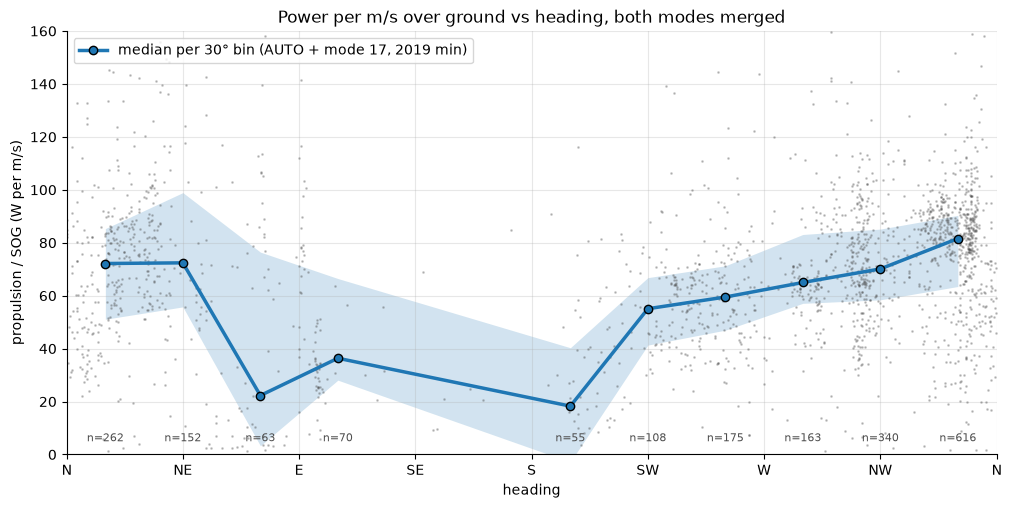

,median,q25,q75,n
bin,,,,
0–30°,72.0,51.0,85.0,262
30–60°,72.0,56.0,99.0,152
60–90°,22.0,3.0,76.0,63
90–120°,36.0,28.0,66.0,70
180–210°,18.0,-3.0,40.0,55
210–240°,55.0,41.0,67.0,108
240–270°,59.0,47.0,71.0,175
270–300°,65.0,57.0,83.0,163
300–330°,70.0,58.0,85.0,340


In [9]:
b = by_heading(hm, "w_per_ms")
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(hm.heading, hm.w_per_ms, ".", ms=2, alpha=0.25, color="#444444")
ax.fill_between(b.x, b.q25, b.q75, color="#1f77b4", alpha=0.2, lw=0)
ax.plot(b.x, b["median"], "-o", ms=6, lw=2.5, color="#1f77b4", mec="k", label=f"median per 30° bin (AUTO + mode 17, {len(hm)} min)")
for x, n in zip(b.x, b.n):
    ax.annotate(f"n={n}", (x, 5), ha="center", fontsize=8, color="0.3")
ax.set_xlim(0, 360); ax.set_xticks(range(0, 361, 45), ["N", "NE", "E", "SE", "S", "SW", "W", "NW", "N"])
ax.set_ylim(0, 160); ax.set_xlabel("heading"); ax.set_ylabel("propulsion / SOG (W per m/s)")
ax.set_title("Power per m/s over ground vs heading, both modes merged")
ax.legend(loc="upper left")
plt.show()
b.assign(bin=[f"{int(x - 15)}–{int(x + 15)}°" for x in b.x]).set_index("bin")[["median", "q25", "q75", "n"]].round(0)

## 5. One panel per day

Tidal currents turn round about every 6 h, so pooled over 17 days a heading effect could cancel out. Each day is its own panel (AUTO and mode 17 together, coloured by mode). Days with fewer than 30 motor-on minutes are left out.

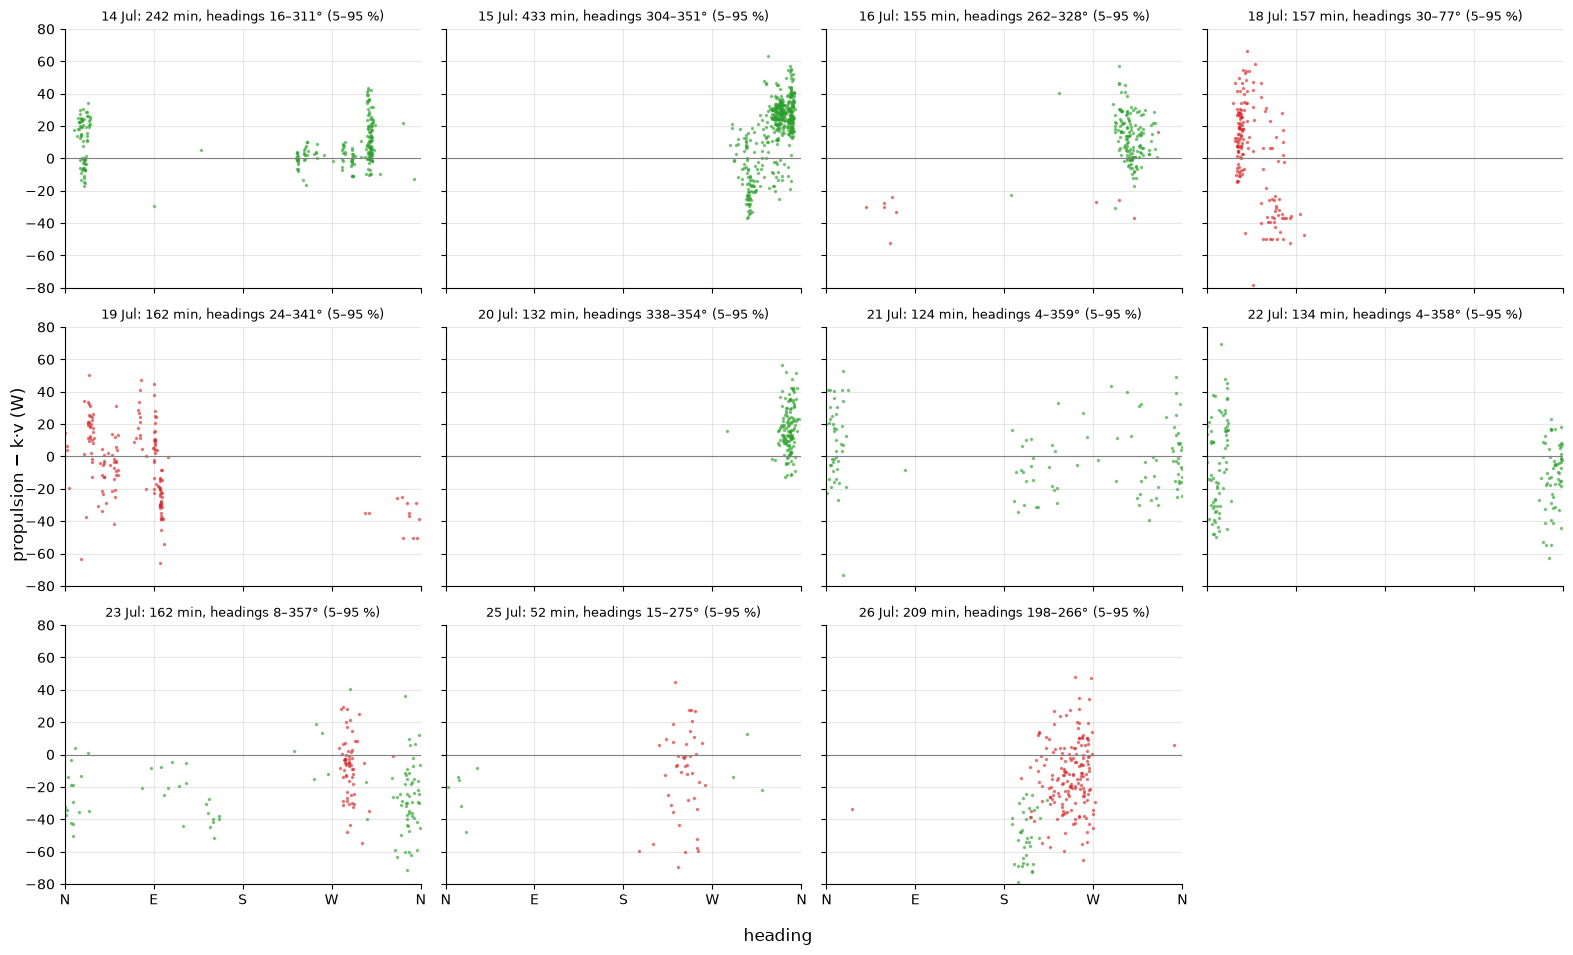

In [10]:
hm["day"] = hm.t.dt.floor("D")
days_h = [d for d, g in hm.groupby("day") if len(g) >= 30]
nc = 4; nr = int(np.ceil(len(days_h) / nc))
fig, axes = plt.subplots(nr, nc, figsize=(16, 3.2 * nr), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()
for ax, d in zip(axes, days_h):
    g = hm[hm.day == d]
    for mode in [10, 17]:
        q = g[g.custom_mode == mode]
        ax.plot(q.heading, q.leftover, ".", ms=3, alpha=0.5, color=MODE_COLORS[mode])
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_title(f"{d:%d %b}: {len(g)} min, headings {g.heading.quantile(0.05):.0f}–{g.heading.quantile(0.95):.0f}° (5–95 %)", fontsize=9)
    ax.set_xlim(0, 360); ax.set_xticks(range(0, 361, 90), ["N", "E", "S", "W", "N"]); ax.set_ylim(-80, 80)
for ax in axes[len(days_h):]:
    ax.axis("off")
fig.supxlabel("heading"); fig.supylabel("propulsion − k·v (W)")
plt.tight_layout(); plt.show()

# Part 3. Both together

One compass. **Bars** = median power per m/s over ground for each heading sector (Part 2, both modes merged): longer = more expensive to go that way. **Arrows** = the time-weighted mean drift with the motor off (Part 1), for MANUAL disarmed, armed and both. If the drift is a current or wind, going *with* the arrows should be cheap and going against them expensive.

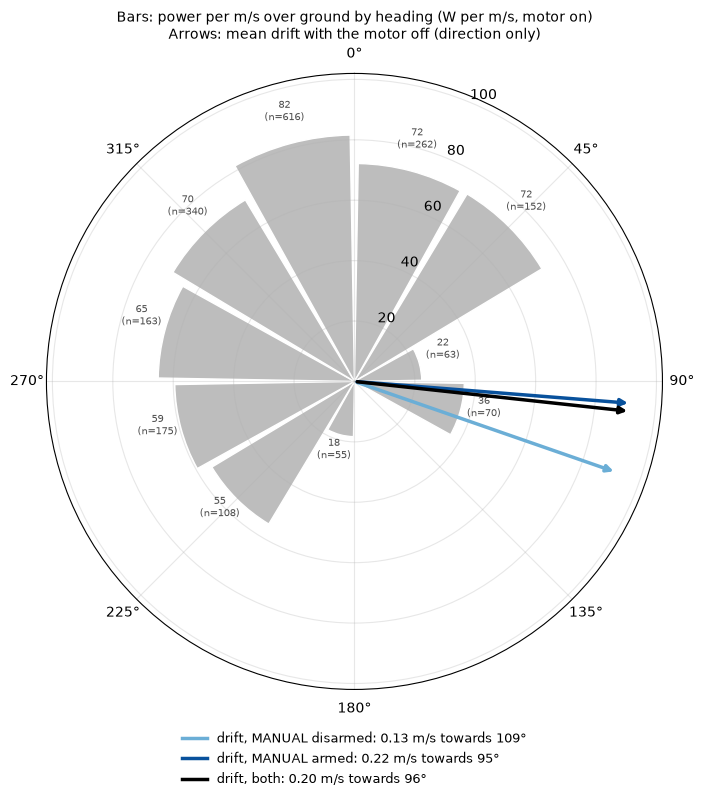

In [11]:
b = by_heading(hm, "w_per_ms")
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"projection": "polar"})
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.bar(np.radians(b.x), b["median"], width=np.radians(28), color="#bdbdbd", edgecolor="white")
for x, v, n in zip(b.x, b["median"], b.n):
    ax.annotate(f"{v:.0f}\n(n={n})", (np.radians(x), v + 8), ha="center", fontsize=7, color="0.3")
rmax = b["median"].max() * 1.25
for name, d, c in [("MANUAL disarmed", avg[avg.kind == "MANUAL disarmed"], ARM_COLORS["MANUAL disarmed"]),
                   ("MANUAL armed", avg[avg.kind == "MANUAL armed"], ARM_COLORS["MANUAL armed"]), ("both", avg, "k")]:
    e, n = mean_drift(d); sp, dr = np.hypot(e, n), np.degrees(np.arctan2(e, n)) % 360
    ax.annotate("", xy=(np.radians(dr), rmax * 0.9), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=c, lw=2.5))
    ax.plot([], [], color=c, lw=2.5, label=f"drift, {name}: {sp:.2f} m/s towards {dr:.0f}°")
ax.set_ylim(0, rmax)
ax.set_title("Bars: power per m/s over ground by heading (W per m/s, motor on)\nArrows: mean drift with the motor off (direction only)", fontsize=10)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.05), fontsize=9, frameon=False)
plt.show()